## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [ ]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["curriculum.py", "data/curriculum_manifest.csv", "real_units.py", "sectors.py", "sector_analysis.py", "alignment.py", "extraction.py", "skill_extractor.py", "skill_extractor_v2.py",
          "job_cleaned.csv", "skills_dictionary.csv", "normalisation.py", "extra_aliases_reviewed.csv"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


# 08 · Case study: are Australian data/AI units aligned with U.S. employer demand? (Member 3)
This notebook answers the group's reframed question on **real unit documents**: 20 public UTS, USYD and UNSW unit pages saved as PDFs in `data/curriculum_pdfs/` (browser print-outs of handbook and outline pages, listed with source URLs in `data/curriculum_manifest.csv`).

**Two groups of units.** *Core* (7): the first units collected, all machine-learning focused. *Added* (13): databases, big-data engineering, statistics, visualisation, data science foundations, NLP and enterprise software, added so that gaps such as SQL are tested fairly.

**Read this before quoting any number.**
* The units are a **case study** of data/AI units (a few per university), not a statement about all Australian higher education or whole degrees.
* The documents are handbook or outline pages, which are **shorter than full unit outlines** (UTS shows only description and learning outcomes), so coverage is a lower bound.
* The extractor was validated on job ads, not unit documents; false matches were reviewed by hand and the few removed are listed with reasons in the manifest.
* The job side is the U.S. benchmark (688 ads); the 14 Australian ads are too few to test separately.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 90)
from skill_extractor_v2 import RequirementAwareExtractor
from extraction import analyse_text
from alignment import job_strengths, DemandModel, curriculum_coverage
from sectors import SECTOR_OF, sector_summary
from sector_analysis import SectorModel
from curriculum import load_curriculum
from real_units import UNITS as TEXT_UNITS
import os; os.makedirs("figures", exist_ok=True)
BLUE, GREY, INK = "#2a78d6", "#b9b8b2", "#0b0b0b"
def save(fig, name): fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
def short(u): return " ".join(u.split()[:2])
jobs = pd.read_csv("job_cleaned.csv", encoding="utf-8-sig")
EX = RequirementAwareExtractor(extra_aliases_path="extra_aliases_reviewed.csv", expand_morphology=True)
S = job_strengths(jobs.job_description, EX)
D = DemandModel(S, jobs.career_category)
M = SectorModel(S, jobs.company, SECTOR_OF, careers=jobs.career_category)
profs, man = load_curriculum()
core = {u: p for u, p in profs.items() if u in set(man[man.group == "core"].unit_id)}
print(len(profs), "units loaded:", len(core), "core +", len(profs) - len(core), "added; by university:", dict(man.university.value_counts()))

20 units loaded: 7 core + 13 added; by university: {'UTS': np.int64(10), 'USYD': np.int64(5), 'UNSW': np.int64(5)}


## 1. What each unit covers
Skills the extractor found in each PDF, after the manual review of false matches (see `excluded_skills` in the manifest).

In [3]:
tbl = pd.DataFrame({"unit": list(profs), "group": [man.set_index("unit_id").group[u] for u in profs],
                    "n": [len(p.skills) for p in profs.values()], "skills": [", ".join(sorted(p.skills)) for p in profs.values()]})
tbl.sort_values(["group", "unit"]).reset_index(drop=True)

,unit,group,n,skills
0,UNSW COMP6713 NLP,added,5,"Artificial Intelligence, Classification, Large Language Models, Named Entity Recogniti..."
1,UNSW COMP9311 Database Systems,added,0,
2,UNSW COMP9321 Data Services Engineering,added,1,Python
3,USYD COMP5046 NLP,added,9,"Classification, Clustering, Deep Learning, Large Language Models, Machine Learning, Na..."
4,USYD COMP5310 Principles of Data Science,added,12,"Classification, Clustering, Data Analysis, Data Visualization, EDA, Hypothesis Testing..."
5,USYD COMP5348 Enterprise Software Architecture,added,1,Cloud Computing
6,UTS 36100 Data Science for Innovation,added,4,"Classification, Clustering, Data Quality, Regression"
7,UTS 36103 Statistical Thinking,added,2,"Data Analysis, Python"
8,UTS 36104 Data Visualisation and Narratives,added,1,Data Visualization
9,UTS 36117 Data Visualisation,added,1,Data Visualization


### Which unit covers which skill?
Rows are the 20 units, columns the 22 skills U.S. employers ask for most (average across the five careers). Darker means the unit covers the skill more strongly (assessed, then taught, then mentioned). Empty columns are gaps for the whole catalogue.

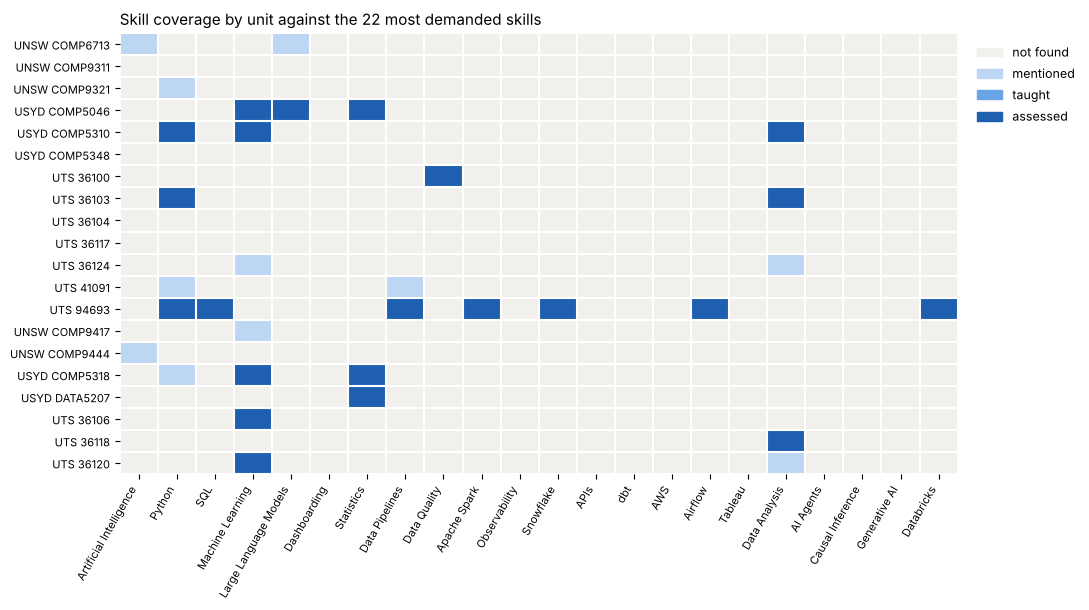

In [4]:
from matplotlib.colors import ListedColormap
topskills = list(D.table().mean().sort_values(ascending=False).head(22).index)
order_units = list(tbl.sort_values(["group", "unit"]).unit)
Z = np.array([[profs[u].skills[s]["weight"] if s in profs[u].skills else 0 for s in topskills] for u in order_units])
cm = ListedColormap(["#f1f0ec", "#bcd6f3", "#6aa3e6", "#1f5fb0"])
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.imshow(np.digitize(Z, [0.01, 0.6, 0.9]), cmap=cm, aspect="auto")
ax.set_xticks(range(len(topskills))); ax.set_xticklabels(topskills, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(order_units))); ax.set_yticklabels([short(u) for u in order_units], fontsize=8)
ax.set_xticks(np.arange(-.5, len(topskills)), minor=True); ax.set_yticks(np.arange(-.5, len(order_units)), minor=True)
ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
for sp in ax.spines.values(): sp.set_visible(False)
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color=c, label=l) for c, l in zip(["#f1f0ec", "#bcd6f3", "#6aa3e6", "#1f5fb0"], ["not found", "mentioned", "taught", "assessed"])],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
ax.set_title("Skill coverage by unit against the 22 most demanded skills", loc="left", fontsize=11)
plt.tight_layout(); save(fig, "fig1_unit_skill_heatmap"); plt.show()

Two things to notice. **UNSW COMP9311 Database Systems finds no skills at all**: its handbook text talks about "relational database management systems", "database design and querying", but never says "SQL", so exact-phrase matching sees nothing. That is the semantic gap Member 4's method targets, and a good example for the report. Likewise UTS 36103 Statistical Thinking says "statistical" but not "Statistics".

In [5]:
cur = curriculum_coverage(profs); cov = {s: d["weight"] for s, d in cur.items()}
print(len(cov), "distinct skills across", len(profs), "units")
pd.DataFrame([{"skill": s, "best level": d["best_level"], "units": len(d["units"])} for s, d in cur.items()]).sort_values(["units", "skill"], ascending=[False, True]).reset_index(drop=True).head(25)

39 distinct skills across 20 units


,skill,best level,units
0,Classification,assessed,8
1,Machine Learning,assessed,7
2,Python,assessed,6
3,Regression,assessed,6
4,Data Analysis,assessed,5
5,Data Visualization,assessed,5
6,Clustering,assessed,4
7,Deep Learning,assessed,4
8,Natural Language Processing,assessed,3
9,Reinforcement Learning,taught,3


## 2. Fit by career (95% range from bootstrapping the job ads)

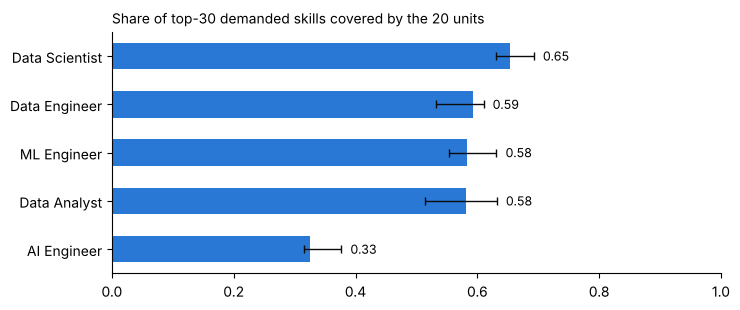

,career,n_ads,fit,ci_low,ci_high
0,Data Scientist,127,0.654,0.630,0.693
1,Data Engineer,57,0.593,0.532,0.610
2,ML Engineer,202,0.582,0.553,0.631
3,Data Analyst,27,0.581,0.513,0.632
4,AI Engineer,275,0.326,0.315,0.377


In [6]:
fc = D.fit(cov, n_boot=500)
fig, ax = plt.subplots(figsize=(7.5, 3.2)); y = np.arange(len(fc))[::-1]
ax.barh(y, fc.fit, color=BLUE, height=0.55)
ax.errorbar(fc.fit, y, xerr=[fc.fit-fc.ci_low, fc.ci_high-fc.fit], fmt="none", ecolor=INK, capsize=3, lw=1)
ax.set_yticks(y); ax.set_yticklabels(fc.career); ax.set_xlim(0, 1)
for yi, v, h in zip(y, fc.fit, fc.ci_high): ax.text(h+0.015, yi, f"{v:.2f}", va="center", fontsize=9)
for sp in ["top","right"]: ax.spines[sp].set_visible(False)
ax.set_title(f"Share of top-30 demanded skills covered by the {len(profs)} units", loc="left", fontsize=10); plt.tight_layout(); save(fig, "fig2_career_fit"); plt.show()
fc.round(3)

Reading it: taking the best coverage across all 20 units, fit is highest for **Data Scientist** (0.65) and about equal for **Data Engineer** (0.59), **ML Engineer** (0.58) and **Data Analyst** (0.58); **AI Engineer** is lowest (0.33), because those ads ask for APIs, agents, observability and cloud tooling that few unit documents name. This is a **catalogue-level** figure (a student would have to take units from all three universities), not any one student's path; see sections 5 and 6 for the breakdown.

## 3. Biggest gaps

In [7]:
print("Data Scientist:"); display(D.gaps(cov, "Data Scientist", k=8, exclude=["Artificial Intelligence"]))
print("ML Engineer:"); display(D.gaps(cov, "ML Engineer", k=6, exclude=["Artificial Intelligence"]))
tab = D.table(); topd = tab.mean().sort_values(ascending=False).head(20)
pd.DataFrame({"mean demand across careers": topd.round(2), "covered": [cov.get(s, 0) for s in topd.index]})

Data Scientist:


,skill,demand,current_coverage,marginal_gain
0,Causal Inference,0.457,0.0,0.457
1,Dashboarding,0.272,0.0,0.272
2,A/B Testing,0.234,0.0,0.234
3,Experiment Design,0.207,0.0,0.207
4,Forecasting,0.181,0.0,0.181
5,dbt,0.106,0.0,0.106
6,Looker,0.071,0.0,0.071
7,PyTorch,0.069,0.0,0.069


ML Engineer:


,skill,demand,current_coverage,marginal_gain
0,PyTorch,0.358,0.0,0.358
1,Generative AI,0.176,0.0,0.176
2,Observability,0.170,0.0,0.170
3,Kubernetes,0.163,0.0,0.163
4,Fine-tuning,0.145,0.0,0.145
5,APIs,0.140,0.0,0.140


,mean demand across careers,covered
Artificial Intelligence,0.66,0.5
Python,0.61,1.0
SQL,0.49,1.0
Machine Learning,0.42,1.0
Large Language Models,0.27,1.0
Dashboarding,0.24,0.0
Statistics,0.22,1.0
Data Pipelines,0.21,1.0
Data Quality,0.17,1.0
Apache Spark,0.17,1.0


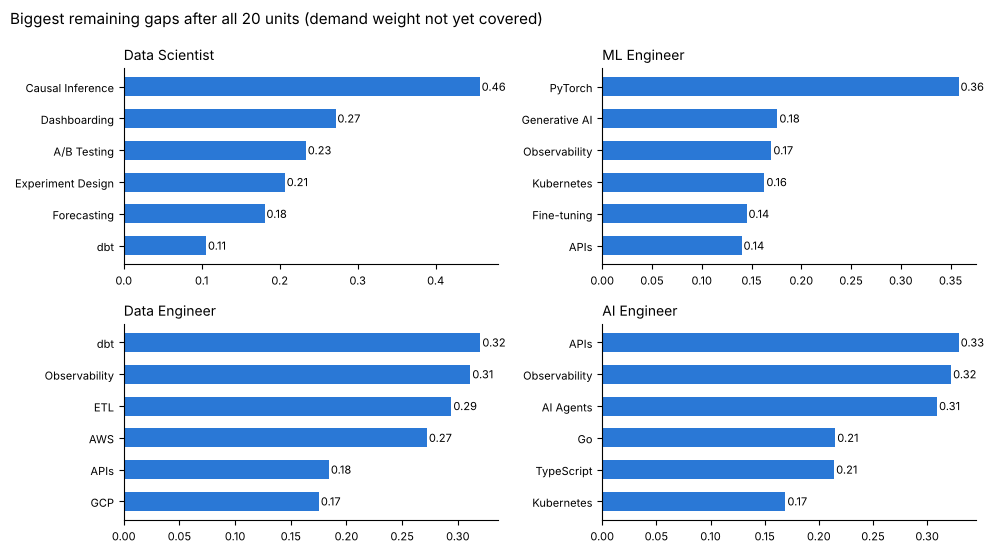

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6))
for ax, car in zip(axes.ravel(), ["Data Scientist", "ML Engineer", "Data Engineer", "AI Engineer"]):
    g = D.gaps(cov, car, k=6, exclude=["Artificial Intelligence"]).iloc[::-1]
    ax.barh(g.skill, g.marginal_gain, color=BLUE, height=0.6)
    for yi, v in enumerate(g.marginal_gain): ax.text(v + 0.002, yi, f"{v:.2f}", va="center", fontsize=8)
    ax.set_title(car, loc="left", fontsize=10); ax.tick_params(labelsize=8)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
fig.suptitle("Biggest remaining gaps after all 20 units (demand weight not yet covered)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); save(fig, "fig3_top_gaps"); plt.show()

## 4. Fit by employer sector (company-clustered 95% range)

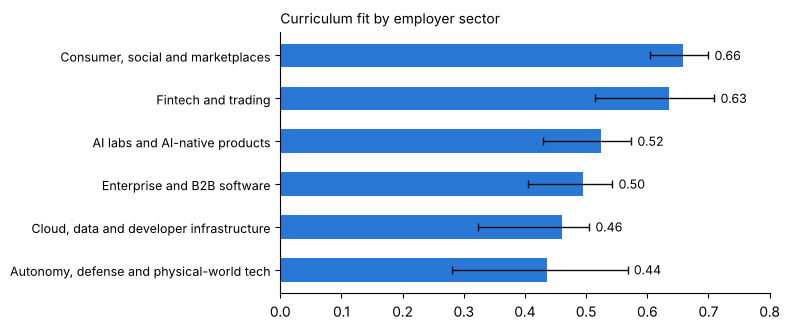

,sector,ads,fit,ci_low,ci_high
0,"Consumer, social and marketplaces",144,0.658,0.604,0.700
1,Fintech and trading,69,0.635,0.514,0.710
2,AI labs and AI-native products,173,0.525,0.430,0.574
3,Enterprise and B2B software,101,0.495,0.405,0.543
4,"Cloud, data and developer infrastructure",107,0.460,0.324,0.505
5,"Autonomy, defense and physical-world tech",72,0.436,0.280,0.568


In [9]:
summ = sector_summary(jobs); MAIN = list(summ[summ.main_sector].sector)
fs = M.fit(cov, n_boot=500); fs = fs[fs.sector.isin(MAIN)].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.4)); y = np.arange(len(fs))[::-1]
ax.barh(y, fs.fit, color=BLUE, height=0.55)
ax.errorbar(fs.fit, y, xerr=[fs.fit-fs.ci_low, fs.ci_high-fs.fit], fmt="none", ecolor=INK, capsize=3, lw=1)
ax.set_yticks(y); ax.set_yticklabels(fs.sector, fontsize=9); ax.set_xlim(0, 0.8)
for yi, v, h in zip(y, fs.fit, fs.ci_high): ax.text(h+0.01, yi, f"{v:.2f}", va="center", fontsize=9)
for sp in ["top","right"]: ax.spines[sp].set_visible(False)
ax.set_title("Curriculum fit by employer sector", loc="left", fontsize=10); plt.tight_layout(); save(fig, "fig5_sector_fit"); plt.show()
fs.round(3)

Consumer, social and marketplace employers fit best (0.66; they want Statistics and Machine Learning, which the units cover) and autonomy, cloud and infrastructure employers fit worst (0.44 to 0.46: Computer Vision, C++, Distributed Systems, Observability). **The intervals overlap heavily**, so only the top-versus-bottom contrast is worth mentioning, and it should be called suggestive.

## 5. By university (descriptive only)
Three to ten units per university, chosen by us, so differences between universities are **not** evidence about the universities.

In [10]:
rows = {}
for uni in ["UTS", "USYD", "UNSW"]:
    ids = list(man[man.university == uni].unit_id)
    c = {s: d["weight"] for s, d in curriculum_coverage({u: profs[u] for u in ids}).items()}
    rows[f"{uni} ({len(ids)} units)"] = D.fit(c, n_boot=20).set_index("career").fit
pd.DataFrame(rows).round(3)

,UTS (10 units),USYD (5 units),UNSW (5 units)
career,,,
AI Engineer,0.173,0.218,0.182
Data Analyst,0.448,0.245,0.109
Data Engineer,0.553,0.122,0.093
Data Scientist,0.405,0.424,0.155
ML Engineer,0.341,0.439,0.217


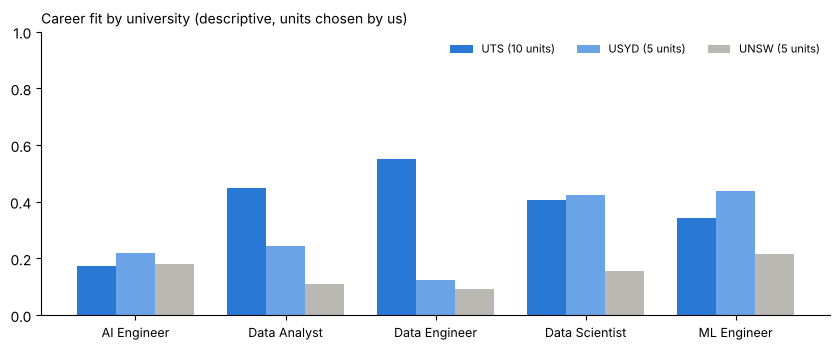

In [11]:
fu = pd.DataFrame(rows); fig, ax = plt.subplots(figsize=(8.5, 3.6)); w = 0.26; x = np.arange(len(fu))
for i, (col, c) in enumerate(zip(fu.columns, [BLUE, "#6aa3e6", GREY])):
    ax.bar(x + (i - 1) * w, fu[col], w, color=c, label=col)
ax.set_xticks(x); ax.set_xticklabels(fu.index, fontsize=9); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.set_title("Career fit by university (descriptive, units chosen by us)", loc="left", fontsize=10); plt.tight_layout(); save(fig, "fig4_by_university"); plt.show()

## 6. Sensitivity checks

In [12]:
cov_core = {s: d["weight"] for s, d in curriculum_coverage(core).items()}
flat = {s: 1.0 for s in cov}
chk = pd.DataFrame({"all units": D.fit(cov, n_boot=20).set_index("career").fit,
                    "core 7 (ML only)": D.fit(cov_core, n_boot=20).set_index("career").fit,
                    "all units, flat weights": D.fit(flat, n_boot=20).set_index("career").fit})
print("distinct skills: all", len(cov), "| core 7 only", len(cov_core)); display(chk.round(3))
gain = pd.DataFrame({"core 7": D.gaps(cov_core, "Data Scientist", k=8, exclude=["Artificial Intelligence"]).set_index("skill").marginal_gain,
                     "all units": D.gaps(cov, "Data Scientist", k=8, exclude=["Artificial Intelligence"]).set_index("skill").marginal_gain})
print("Data Scientist gap size (marginal gain) before and after adding the 13 units:")
dsg = D.gaps(cov_core, "Data Scientist", k=12, exclude=["Artificial Intelligence"])[["skill", "marginal_gain"]].rename(columns={"marginal_gain": "gap, core 7"}).set_index("skill")
dsg["gap, all units"] = [round((D.demand("Data Scientist")[D.index[s]]) * (1 - cov.get(s, 0)), 3) for s in dsg.index]
dsg.round(3)

distinct skills: all 39 | core 7 only 20


,all units,core 7 (ML only),"all units, flat weights"
career,,,
AI Engineer,0.326,0.172,0.417
Data Analyst,0.581,0.225,0.626
Data Engineer,0.593,0.129,0.634
Data Scientist,0.654,0.357,0.698
ML Engineer,0.582,0.366,0.674


Data Scientist gap size (marginal gain) before and after adding the 13 units:


,"gap, core 7","gap, all units"
skill,,
SQL,0.805,0.000
Causal Inference,0.457,0.457
Python,0.395,0.000
Dashboarding,0.272,0.272
A/B Testing,0.234,0.234
Large Language Models,0.230,0.000
Experiment Design,0.207,0.207
Forecasting,0.181,0.181
Apache Spark,0.128,0.000


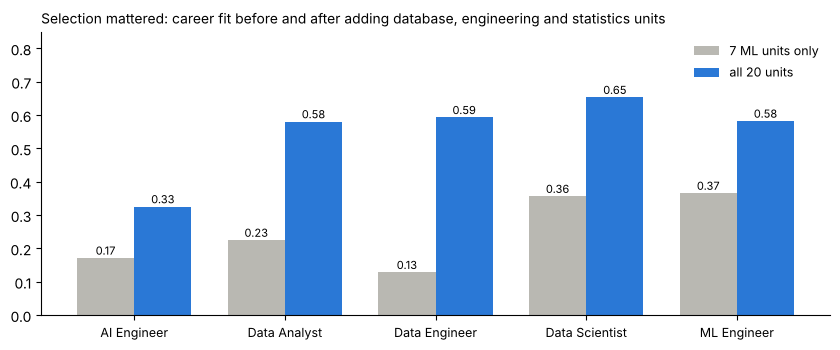

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 3.6)); x = np.arange(len(chk)); w = 0.38
ax.bar(x - w/2, chk["core 7 (ML only)"], w, color=GREY, label="7 ML units only")
ax.bar(x + w/2, chk["all units"], w, color=BLUE, label="all 20 units")
for xi, a, b in zip(x, chk["core 7 (ML only)"], chk["all units"]):
    ax.text(xi - w/2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8); ax.text(xi + w/2, b + 0.01, f"{b:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(chk.index, fontsize=9); ax.set_ylim(0, 0.85); ax.legend(frameon=False, fontsize=9)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.set_title("Selection mattered: career fit before and after adding database, engineering and statistics units", loc="left", fontsize=10)
plt.tight_layout(); save(fig, "fig6_selection_effect"); plt.show()

In [14]:
# the original page-text version of the core units (condensed copy in real_units.py): same ranking?
profs_text = {u: analyse_text(t) for u, t in TEXT_UNITS.items()}
cov_text = {s: d["weight"] for s, d in curriculum_coverage(profs_text).items()}
print("core 7 from PDFs:", len(cov_core), "skills | core 7 from page text:", len(cov_text), "skills")
pd.DataFrame({"core 7 PDFs": D.fit(cov_core, n_boot=20).set_index("career").fit, "core 7 page text": D.fit(cov_text, n_boot=20).set_index("career").fit}).round(3)

core 7 from PDFs: 20 skills | core 7 from page text: 22 skills


,core 7 PDFs,core 7 page text
career,,
AI Engineer,0.172,0.271
Data Analyst,0.225,0.234
Data Engineer,0.129,0.163
Data Scientist,0.357,0.368
ML Engineer,0.366,0.502


**What the checks say.**
* **Selection mattered most.** With only the 7 ML units, Data Engineer fit was 0.13 and SQL, Spark and Snowflake were gaps. Adding the databases, big-data engineering, statistics and visualisation units lifts Data Engineer to 0.59 and closes the SQL, Spark and Snowflake gaps (SQL is covered only by UTS 94693 Big Data Engineering, because the UNSW database handbook page never names SQL). So the first, ML-only picture would have **overstated** how much Australian units miss.
* **Gaps that remain across all 20 units:** for Data Scientist, Causal Inference, Dashboarding, A/B Testing, Experiment Design and Forecasting; for ML Engineer, PyTorch (named on the UNSW WebCMS3 outline but not on the handbook page), Generative AI, Observability and Kubernetes; for Data Engineer, dbt, ETL, cloud platforms (AWS, GCP, Azure) and observability; for AI Engineer, APIs, agents and RAG.
* **Weights barely matter.** With flat weights (every mention counts fully) the top and bottom careers are the same and the middle three move by under 0.1.
* **PDFs versus page text (core 7):** both put ML Engineer and Data Scientist on top; ML Engineer reads 0.37 from the PDFs and 0.50 from the page text, because the WebCMS3 text names PyTorch and LLMs that the handbook PDF does not.

## 7. What the real PDFs taught us about the pipeline
Running the reader on real browser print-outs found these problems, all fixed with a regression test: (1) print headers padded with long runs of spaces were not recognised as running headers, so title words were credited to every page; (2) indented wrapped lines were not rejoined; (3) requisite lists, excluded courses, field-of-education codes and "further study" sentences were credited as coverage; (4) table cells and side columns were glued into one line, which inflated "assessed" levels and credited assessment-policy tables ("AI allowed", exam weights) as skills. "Topics covered include ..." now counts as *taught*.

Remaining issues are handled by transparent manual review (`excluded_skills` in the manifest): server clustering read as ML clustering (COMP5348), a cost note read as cloud computing (COMP5046), and an AI-usage policy sentence (COMP5310). Print quality still varies: UTS shows only description and learning outcomes (topics and assessment are on Canvas), and exact-phrase matching misses concepts that are described but not named (COMP9311, UTS 36103).

## 8. Limitations (put these in the report)
* A case study of 20 data/AI units (UTS 10, USYD 5, UNSW 5), chosen by us; not all of Australian higher education, and not whole degrees.
* Handbook PDFs are shorter than full unit outlines, so coverage is a lower bound (most for UTS).
* Exact-phrase matching misses described-but-unnamed skills (a database unit with no SQL match). Member 4's semantic method targets this.
* The extractor was validated on job ads (F1 0.94 on 30 ads), not on unit documents; three matches were removed by manual review, with reasons in the manifest.
* The U.S. benchmark is mostly large tech employers and mostly 2026 ads.